# 02. Baseline Forecasts and Accuracy Benchmark

**Project 1: Forecast Accuracy Benchmark + Forecast Value Added (FVA)**

**Business question for this notebook:** For each product category at store CA_1, which forecasting method is most accurate over a one-quarter horizon, and is it biased?

**Input:** `data/processed/weekly_sku_CA_1.parquet` (from notebook 01)

**Outputs**
- `data/processed/forecasts_test_CA_1.parquet`: every method's forecast for every SKU-week in the test quarter (notebook 03 uses this for FVA)
- `outputs/figures/wape_by_method_CA_1.png`: accuracy by method and category

**Steps**
1. Split into training history and a 13-week test quarter
2. Build five forecasts: naive, seasonal naive, moving average, Holt-Winters, LightGBM
3. Score with WAPE, bias, and MAPE, by method and category

## Setup

In [1]:
import time
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")  # statsmodels prints many convergence notes

STORE_ID = "CA_1"
HORIZON = 13         # test quarter length in weeks
MIN_TRAIN_WEEKS = 104  # 2 full years, needed to learn yearly seasonality
SEASON = 52          # weeks in a year
MA_WINDOW = 4        # moving average window in weeks

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIG_DIR = PROJECT_DIR / "outputs" / "figures"

weekly = pd.read_parquet(PROCESSED_DIR / f"weekly_sku_{STORE_ID}.parquet")
weekly = weekly.sort_values(["item_id", "wm_yr_wk"]).reset_index(drop=True)
print(f"Loaded {len(weekly):,} SKU-weeks, {weekly['item_id'].nunique():,} SKUs")

Loaded 683,167 SKU-weeks, 3,049 SKUs


## Step 2. Train/test split

We pretend it is the end of the training period and a planner must forecast the **next 13 weeks (one quarter)**. The real sales in those 13 weeks are the **test set**: we only look at them to score forecasts.

This is a **fixed-origin** forecast: all 13 weeks are forecast at once from the same point in time, the way a quarterly plan is made. Week 1 of the test is a 1-week-ahead forecast; week 13 is 13 weeks ahead.

**Which SKUs are scored:** only SKUs with at least 104 training weeks (2 years). Holt-Winters and seasonal naive need at least one full prior year, and Holt-Winters needs two to estimate a yearly pattern. Newer SKUs are excluded from the benchmark and listed as a limitation.

In [2]:
weeks = np.sort(weekly["wm_yr_wk"].unique())
test_weeks = weeks[-HORIZON:]
cutoff = test_weeks[0]  # first test week

train = weekly[weekly["wm_yr_wk"] < cutoff]
test = weekly[weekly["wm_yr_wk"] >= cutoff]

train_len = train.groupby("item_id").size()
eligible = train_len[train_len >= MIN_TRAIN_WEEKS].index
# Also require a sale price in every test week (item still on the shelf)
test_counts = test.groupby("item_id").size()
eligible = eligible.intersection(test_counts[test_counts == HORIZON].index)

train = train[train["item_id"].isin(eligible)]
test = test[test["item_id"].isin(eligible)].copy()

print(f"Training weeks: up to {train['week_start'].max().date()}")
print(f"Test weeks:     {test['week_start'].min().date()} to {test['week_start'].max().date()} ({HORIZON} weeks)")
print(f"SKUs scored:    {len(eligible):,} of {weekly['item_id'].nunique():,}")
print(test.groupby("cat_id")["item_id"].nunique().rename("SKUs scored"))

Training weeks: up to 2016-02-13
Test weeks:     2016-02-20 to 2016-05-14 (13 weeks)
SKUs scored:    2,717 of 3,049
cat_id
FOODS        1274
HOBBIES       512
HOUSEHOLD     931
Name: SKUs scored, dtype: int64


## Step 3. Build the forecasts

Notation used below:
- $y_t$ = actual units sold in week $t$
- $T$ = the last training week
- $\hat{y}_{T+h}$ = forecast for $h$ weeks after $T$, where $h = 1, \dots, 13$

### Method 1: Naive
$$\hat{y}_{T+h} = y_T$$
Every future week equals the last week we saw. It is the standard benchmark: if a method cannot beat naive, it is not adding value. This is also the baseline for FVA in notebook 03.

### Method 2: Seasonal naive
$$\hat{y}_{T+h} = y_{T+h-52}$$
Each future week equals the same week one year earlier. Captures yearly patterns (holidays, seasons) but repeats last year's noise too.

### Method 3: Moving average (4 weeks)
$$\hat{y}_{T+h} = \frac{1}{4}\sum_{i=0}^{3} y_{T-i}$$
The average of the last 4 weeks, held flat. Smooths out one-off spikes.

In [3]:
def last_n(s, n):
    return s.iloc[-n:].to_numpy(dtype=float)

fc = test[["item_id", "dept_id", "cat_id", "wm_yr_wk", "week_start", "units", "sell_price"]].copy()
fc["h"] = fc.groupby("item_id").cumcount() + 1  # 1..13 weeks ahead

g = train.groupby("item_id")["units"]
naive = g.last().astype(float)
ma = g.apply(lambda s: last_n(s, MA_WINDOW).mean())

fc["naive"] = fc["item_id"].map(naive)
fc["moving_avg"] = fc["item_id"].map(ma)

# Seasonal naive: actual sales 52 weeks before each test week
lookup = weekly.set_index(["item_id", "wm_yr_wk"])["units"]
week_pos = {wk: i for i, wk in enumerate(weeks)}
fc["wk_last_year"] = fc["wm_yr_wk"].map(lambda wk: weeks[week_pos[wk] - SEASON])
fc["seasonal_naive"] = [
    float(lookup.get((i, wk), np.nan)) for i, wk in zip(fc["item_id"], fc["wk_last_year"])
]
fc = fc.drop(columns="wk_last_year")
print("Missing seasonal naive values:", fc["seasonal_naive"].isna().sum())

Missing seasonal naive values: 0


### Method 4: Holt-Winters (exponential smoothing)
Holt-Winters keeps three running estimates for each SKU and updates them every week, giving more weight to recent weeks:
- **Level** $\ell_t$: the current baseline sales rate
- **Trend** $b_t$: how fast the level is rising or falling
- **Season** $s_t$: how much this week of the year sits above or below the baseline

Forecast:
$$\hat{y}_{T+h} = \ell_T + (\phi + \phi^2 + \dots + \phi^h)\, b_T + s_{T+h-52}$$

- $\phi$ (phi, between 0 and 1) **damps** the trend so it flattens out over time. Without damping, a short upswing can be projected upward for the whole quarter.
- The weights for level, trend, and season ($\alpha$, $\beta$, $\gamma$) and $\phi$ are fitted separately for each SKU.
- Forecasts below 0 are set to 0 (you cannot sell negative units).

This fits one model per SKU, so it runs in parallel across your CPU cores. Expect a few minutes.

In [4]:
def holt_winters(item_id, y):
    try:
        model = ExponentialSmoothing(
            y.astype(float), trend="add", damped_trend=True,
            seasonal="add", seasonal_periods=SEASON,
            initialization_method="estimated",
        ).fit()
        f = model.forecast(HORIZON)
    except Exception:
        f = np.full(HORIZON, np.nan)  # fall back below if a fit fails
    return item_id, np.clip(f, 0, None)

start = time.time()
series = [(i, s.to_numpy()) for i, s in train.groupby("item_id")["units"]]
results = Parallel(n_jobs=-1)(delayed(holt_winters)(i, y) for i, y in series)
print(f"Fitted {len(results):,} Holt-Winters models in {time.time() - start:.0f} seconds")

hw = pd.DataFrame(
    [(i, h + 1, v) for i, f in results for h, v in enumerate(f)],
    columns=["item_id", "h", "holt_winters"],
)
fc = fc.merge(hw, on=["item_id", "h"], how="left")
failed = fc.loc[fc["holt_winters"].isna(), "item_id"].nunique()
print(f"SKUs where the fit failed (filled with seasonal naive): {failed}")
fc["holt_winters"] = fc["holt_winters"].fillna(fc["seasonal_naive"])

/Users/akashsahadevan/Github/Supply-Chain-Analytics/project-1-forecast-fva/.venv/lib/python3.11/site-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)
/Users/akashsahadevan/Github/Supply-Chain-Analytics/project-1-forecast-fva/.venv/lib/python3.11/site-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)
/Users/akashsahadevan/Github/Supply-Chain-Analytics/project-1-forecast-fva/.venv/lib/python3.11/site-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)
/Users/akashsahadevan/Github/Supply-Chain-Analytics/project-1-forecast-fva/.venv/lib/python3.11/site

Fitted 2,717 Holt-Winters models in 75 seconds
SKUs where the fit failed (filled with seasonal naive): 0


### Method 5: LightGBM (machine learning)
Instead of one model per SKU, LightGBM learns **one model across all SKUs**. It builds hundreds of small decision trees, each correcting the errors of the ones before it (**gradient boosting**).

**Features (inputs) for predicting week $t$:**
- **Lagged sales:** sales 13, 14, 26, and 52 weeks earlier, and averages of the 4 and 13 weeks ending 13 weeks earlier
- **Calendar:** week of year
- **Price:** this week's price, and price relative to the item's average price (captures promotions and price changes)
- **Events:** number of event days and SNAP days in the week
- **Product:** department and category

**Why lags start at 13 weeks:** the forecast is made once at the start of the quarter. For week 13 of the test, the most recent sales we would actually have are from 13 weeks earlier. Using a shorter lag would let the model "see the future," which inflates accuracy. This is called **data leakage**.

**Assumption to state in the README:** price, events, and SNAP days in the test quarter are treated as known in advance. Retailers plan prices and know the holiday calendar ahead of time, so this is realistic, but it is still an assumption.

In [5]:
df = weekly[weekly["item_id"].isin(eligible)].copy()
df["week_of_year"] = df["week_start"].dt.isocalendar().week.astype(int)
gu = df.groupby("item_id")["units"]
for lag in [13, 14, 26, 52]:
    df[f"lag_{lag}"] = gu.shift(lag)
df["roll_mean_4_lag13"] = gu.transform(lambda s: s.shift(13).rolling(4).mean())
df["roll_mean_13_lag13"] = gu.transform(lambda s: s.shift(13).rolling(13).mean())

# Average price from training weeks only, so the test quarter does not leak in
avg_price = df[df["wm_yr_wk"] < cutoff].groupby("item_id")["sell_price"].mean()
df["price_ratio"] = df["sell_price"] / df["item_id"].map(avg_price)
for c in ["dept_id", "cat_id"]:
    df[c] = df[c].astype("category")

FEATURES = [
    "lag_13", "lag_14", "lag_26", "lag_52", "roll_mean_4_lag13", "roll_mean_13_lag13",
    "week_of_year", "sell_price", "price_ratio", "event_days", "snap_days", "dept_id", "cat_id",
]

tr = df[(df["wm_yr_wk"] < cutoff)].dropna(subset=["lag_52"])
te = df[df["wm_yr_wk"] >= cutoff]

model = lgb.LGBMRegressor(
    objective="tweedie",  # suits sales data: many zeros, long right tail
    n_estimators=500, learning_rate=0.05, num_leaves=63,
    min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    random_state=42, verbose=-1,
)
start = time.time()
model.fit(tr[FEATURES], tr["units"])
print(f"Trained on {len(tr):,} SKU-weeks in {time.time() - start:.0f} seconds")

te = te.assign(lightgbm=np.clip(model.predict(te[FEATURES]), 0, None))
fc = fc.merge(te[["item_id", "wm_yr_wk", "lightgbm"]], on=["item_id", "wm_yr_wk"], how="left")

importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=False)
print("\nTop features (number of tree splits):")
print(importance.head(8).to_string())

Trained on 475,717 SKU-weeks in 5 seconds

Top features (number of tree splits):
sell_price            5675
price_ratio           5513
week_of_year          3756
roll_mean_13_lag13    3472
lag_52                2970
roll_mean_4_lag13     2299
lag_26                1913
dept_id               1796


**About the Tweedie objective:** a normal regression assumes errors are symmetric around the forecast. Weekly SKU sales are not: many weeks are 0 or near 0, and a few are very high. The **Tweedie** loss is built for exactly this shape, so it is the standard choice for retail unit sales.

## Step 4. Score the forecasts

Notation: for every SKU-week in the test set, $A$ = actual units, $F$ = forecast units. Sums run over all SKU-weeks in the group being scored.

**WAPE (Weighted Absolute Percentage Error)**, the main KPI:
$$\text{WAPE} = \frac{\sum |A - F|}{\sum A}$$
Total units missed divided by total units sold. Lower is better. It works when some weeks have $A = 0$, and big sellers count more than slow sellers, which matches business impact.

**Bias:**
$$\text{Bias} = \frac{\sum (F - A)}{\sum A}$$
Positive = over-forecasting (risk of excess inventory). Negative = under-forecasting (risk of stockouts). A good forecast has bias close to 0. WAPE tells you how big the errors are; bias tells you which direction they lean.

**MAPE (Mean Absolute Percentage Error):**
$$\text{MAPE} = \frac{1}{n}\sum \frac{|A - F|}{A}$$
The average of each week's percentage error. It **cannot be calculated when $A = 0$** (division by zero), so we compute it only on weeks with sales, and $n$ = the number of those weeks. Even then, a slow seller that sells 1 unit against a forecast of 3 counts as a 200% error, the same weight as a top seller's error. That is why MAPE is shown for reference only.

In [6]:
METHODS = ["naive", "seasonal_naive", "moving_avg", "holt_winters", "lightgbm"]
LABELS = {
    "naive": "Naive", "seasonal_naive": "Seasonal naive", "moving_avg": "Moving avg (4 wk)",
    "holt_winters": "Holt-Winters", "lightgbm": "LightGBM",
}

def score(group):
    A = group["units"].to_numpy(dtype=float)
    rows = {}
    nz = A > 0
    for m in METHODS:
        F = group[m].to_numpy(dtype=float)
        rows[m] = {
            "WAPE": np.abs(A - F).sum() / A.sum(),
            "Bias": (F - A).sum() / A.sum(),
            "MAPE (non-zero weeks)": np.mean(np.abs(A[nz] - F[nz]) / A[nz]),
        }
    return pd.DataFrame(rows).T

print("Share of test SKU-weeks with zero sales:", f"{(fc['units'] == 0).mean():.1%}")
overall = score(fc).rename(index=LABELS).sort_values("WAPE")
overall.style.format("{:.1%}").set_caption("All scored SKUs, test quarter")

Share of test SKU-weeks with zero sales: 15.9%


,WAPE,Bias,MAPE (non-zero weeks)
Moving avg (4 wk),42.7%,-5.5%,62.3%
LightGBM,46.0%,-8.4%,59.4%
Naive,47.7%,-4.9%,71.7%
Holt-Winters,48.7%,-0.8%,67.8%
Seasonal naive,61.5%,-3.4%,83.2%


In [12]:
by_cat = pd.concat({cat: score(g) for cat, g in fc.groupby("cat_id")}, names=["cat_id", "method"])
wape_table = by_cat["WAPE"].unstack("method")[METHODS].rename(columns=LABELS)
bias_table = by_cat["Bias"].unstack("method")[METHODS].rename(columns=LABELS)

print("WAPE by category (lower is better)")
display(wape_table.style.format("{:.1%}").highlight_min(axis=1, color="#36C923E1"))
print("Bias by category (closer to 0 is better; + = over-forecast, - = under-forecast)")
display(bias_table.style.format("{:+.1%}"))

WAPE by category (lower is better)


method,Naive,Seasonal naive,Moving avg (4 wk),Holt-Winters,LightGBM
cat_id,,,,,
FOODS,46.4%,61.1%,42.0%,48.6%,46.1%
HOBBIES,54.0%,64.6%,45.9%,52.5%,47.5%
HOUSEHOLD,48.6%,61.2%,43.3%,46.8%,44.9%


Bias by category (closer to 0 is better; + = over-forecast, - = under-forecast)


method,Naive,Seasonal naive,Moving avg (4 wk),Holt-Winters,LightGBM
cat_id,,,,,
FOODS,-7.7%,-3.8%,-7.7%,-2.5%,-12.6%
HOBBIES,+1.7%,+1.4%,-0.7%,+2.7%,+2.8%
HOUSEHOLD,+0.5%,-4.8%,-1.4%,+2.9%,-1.4%


### Chart: accuracy by method and category

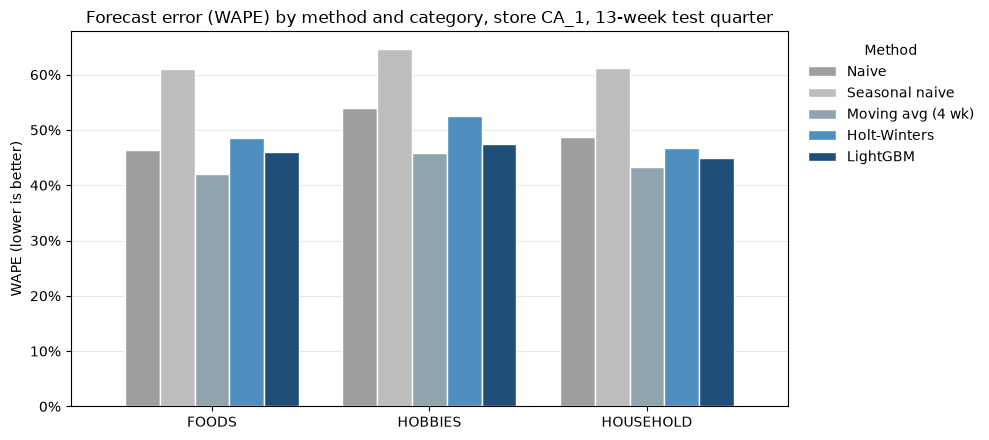

In [8]:
colors = ["#9e9e9e", "#bdbdbd", "#90a4ae", "#4f8fc0", "#1f4e79"]
ax = wape_table.plot(kind="bar", figsize=(10, 4.5), color=colors, width=0.8, edgecolor="white")
ax.set_title(f"Forecast error (WAPE) by method and category, store {STORE_ID}, {HORIZON}-week test quarter")
ax.set_xlabel("")
ax.set_ylabel("WAPE (lower is better)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(title="Method", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / f"wape_by_method_{STORE_ID}.png", dpi=150, bbox_inches="tight")
plt.show()

### Does accuracy get worse further out?
Forecasts for week 1 of the quarter use more recent information than forecasts for week 13. This table shows WAPE by forecast horizon $h$ (weeks ahead).

In [9]:
by_h = pd.concat({h: score(g)["WAPE"] for h, g in fc.groupby("h")}, axis=1).T.rename(columns=LABELS)
by_h.index.name = "weeks ahead (h)"
by_h.style.format("{:.1%}")

,Naive,Seasonal naive,Moving avg (4 wk),Holt-Winters,LightGBM
weeks ahead (h),,,,,
1,38.4%,61.2%,33.6%,38.5%,44.8%
2,40.8%,66.1%,35.8%,43.8%,46.5%
3,42.6%,63.2%,38.1%,43.6%,47.8%
4,45.2%,66.3%,39.8%,48.3%,47.5%
5,45.2%,64.3%,40.5%,48.2%,49.5%
6,45.6%,67.5%,42.4%,49.0%,47.8%
7,46.7%,62.6%,43.1%,50.0%,47.7%
8,51.5%,63.4%,46.6%,55.4%,49.4%
9,49.0%,58.0%,44.6%,49.9%,43.6%


## Save forecasts for notebook 03 (FVA)

In [10]:
out = PROCESSED_DIR / f"forecasts_test_{STORE_ID}.parquet"
fc.to_parquet(out, index=False)
print(f"Saved {len(fc):,} rows to {out.relative_to(PROJECT_DIR)}")

Saved 35,321 rows to data/processed/forecasts_test_CA_1.parquet


## Reading the results (fill in after running)
Write 3 to 5 bullets in your own words, based on the tables above. Prompts:
- Which method has the lowest WAPE overall, and in each category? By how many percentage points does it beat naive?
    - The 4-week moving average wins overall: 42.7% vs naive’s 47.7%, so 5.0 points better
    - It wins every category: FOODS by 4.4 points, HOUSEHOLD by 5.3, HOBBIES by 8.1
    - Why: naive bets everything on one week. Averaging 4 weeks cancels out random highs and lows.
    - What it means: switching from naive to a 4-week average cuts forecast error by about 10%, at no cost.

- Does the best method change by category? (If yes, that is the "method per product group" recommendation.)
    - By category, no. The moving average wins all three.
    - By horizon, yes. The moving average is best for weeks 1 to 8, and LightGBM is best for weeks 9 to 13. For example, at week 12 it’s 42.9% vs 47.7%.
    - Why: the moving average relies on recent sales, which go stale the further out you forecast. LightGBM relies on seasonality, price, and events, which don’t go stale.
    - What it means: use the moving average for near-term replenishment (the next 1 to 8 weeks) and LightGBM for the back half of the quarter.
    
- Which methods lean toward over-forecasting or under-forecasting (bias)? Which is riskier for inventory?
    - Overall, every method under-forecasts. LightGBM is the most (−8.4%) and Holt-Winters the least (−0.8%).
    - The biggest miss is LightGBM in FOODS at −12.6%. HOBBIES is slightly over-forecast by every method (+1 to +3%).
    - Why: FOODS grew about 15% this quarter, and methods that lean on older data lagged behind.
    - Which is riskier: for FOODS this quarter, under-forecasting, because it means empty shelves and lost sales. Over-forecasting food has its own cost (spoilage), so neither direction is free.
    - What it means: track bias separately from WAPE. Holt-Winters has almost no bias but isn’t the most accurate. Low bias and low error are different things.

- How much worse is MAPE than WAPE, and why? (Hint: slow sellers and zero weeks.)
    - MAPE is 13 to 24 points higher for every method. For the moving average it’s 62.3% vs 42.7%, a 19.6-point gap.
    - Why: MAPE counts every week equally, so slow sellers blow it up. Selling 1 unit against a forecast of 3 is a 200% error. Weeks with zero sales (15.9% of the test) can’t be scored at all and are dropped.
    - WAPE weights by volume, so fast sellers drive it. They’re 78% of units. Slow sellers are only 5%.
    - It also changes the winner: MAPE picks LightGBM, while WAPE picks the moving average.
    - What it means: a company that judged forecasts by MAPE would be optimizing for its least important products. That’s why WAPE is the main KPI.

**Limitations to carry into the README**
- One store, one test quarter. Results could differ for another quarter or store
- SKUs with less than 2 years of history are not scored
- Forecasts predict sales, not true demand (stockouts are not visible)
- LightGBM assumes test-quarter prices and events are known in advance